In [1]:
import pandas, numpy, scipy, re

In [2]:
import sklearn, sklearn.preprocessing, sklearn.decomposition

In [3]:
import matplotlib, matplotlib.pyplot
matplotlib.rcParams.update({'font.size':20, 
                            'font.family':'sans-serif', 
                            'xtick.labelsize':16, 
                            'ytick.labelsize':16, 
                            'figure.figsize':(16*(2/3), 9*(2/3)), 
                            'axes.labelsize':20
                           })

# 0. user-defined variables

In [4]:
input_file = '/Users/adrian/research/bmcbf/094/results/profiles/DESeq2_TPM_values.newnames.tsv'

# 1. read expression

In [5]:
expression = pandas.read_csv(input_file, sep='\t', index_col=0)
print(expression.shape)
expression

# get rid of teh CPAD samples
expression = expression.loc[:, ~expression.columns.str.contains('CPAD')]
print(expression.shape)

(39546, 24)
(39546, 12)


In [6]:
for element in expression.columns:
    print(element)

AEG13_AZM_1
AEG13_AZM_2
AEG13_AZM_3
AEG13_DMSO_1
AEG13_DMSO_2
AEG13_DMSO_3
AEG14_DMSO_1
AEG14_DMSO_2
AEG14_DMSO_3
AEG14_EP317_1
AEG14_EP317_2
AEG14_EP317_3


# 3. filter and transform

In [7]:
groups = pandas.Series([re.sub(r'\d+$', '', c) for c in expression.columns],
                       index=expression.columns, name='group')

print(groups.index.to_series().groupby(groups.values).agg(list))   # check grouping

group_medians = expression.T.groupby(groups).median().T            # genes × conditions

substantial_expression = expression[group_medians.max(axis=1) >= 2]
high_expression        = expression[group_medians.max(axis=1) >= 100]
print(substantial_expression.shape, high_expression.shape)

AEG13_AZM_            [AEG13_AZM_1, AEG13_AZM_2, AEG13_AZM_3]
AEG13_DMSO_        [AEG13_DMSO_1, AEG13_DMSO_2, AEG13_DMSO_3]
AEG14_DMSO_        [AEG14_DMSO_1, AEG14_DMSO_2, AEG14_DMSO_3]
AEG14_EP317_    [AEG14_EP317_1, AEG14_EP317_2, AEG14_EP317_3]
dtype: object
(11966, 12) (1009, 12)


In [8]:
group_medians

group,AEG13_AZM_,AEG13_DMSO_,AEG14_DMSO_,AEG14_EP317_
ENSG00000000003.15,6.178072,7.743843,7.069473,6.626069
ENSG00000000005.6,0.000000,0.000000,0.000000,0.000000
ENSG00000000419.14,105.653503,107.096641,112.728705,118.228811
ENSG00000000457.14,8.963118,9.224226,9.178815,8.791572
ENSG00000000460.17,11.129310,12.661063,13.796534,13.407216
...,...,...,...,...
ENSG00000291297.1,0.000000,0.000000,0.077277,0.000000
ENSG00000291298.1,0.000000,0.000000,0.000000,0.000000
ENSG00000291299.1,1.800866,1.688838,1.891630,1.794607
ENSG00000291300.1,0.000000,0.000000,0.000000,0.000000


In [9]:
transpose = substantial_expression.transpose()
pca_substantial_expression = numpy.log2(transpose + 1)

transpose = high_expression.transpose()
pca_high_expression = numpy.log2(transpose + 1)

# 4. visualize substantial expression

In [12]:
scaled_data = sklearn.preprocessing.StandardScaler().fit_transform(pca_substantial_expression)
model = sklearn.decomposition.PCA(n_components=2)
new = model.fit_transform(scaled_data)
explained = model.explained_variance_ratio_
print(explained)

[0.27217733 0.20189021]


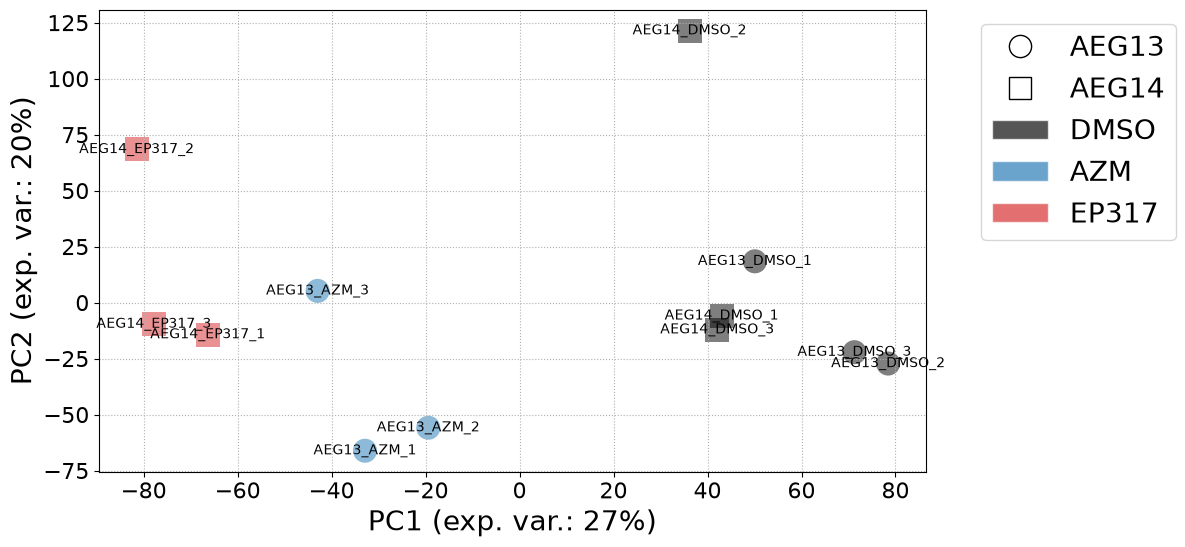

In [33]:
for i in range(len(new)):

    name = pca_substantial_expression.index[i]

    # colors
    if 'AZM' in name:
        the_color = 'tab:blue'
    elif 'EP317' in name:
        the_color = 'tab:red'
    elif 'DMSO' in name:
        the_color = 'black'
    else:
        print('error')

    # marker
    if '13' in name:
        the_marker = 'o'
    elif '14' in name:
        the_marker = 's'
    else:
        print('error')
        
    matplotlib.pyplot.scatter(new[i,0], new[i,1], s=300, c=the_color, marker=the_marker, alpha=0.5, edgecolors='none')
    epsilon=0; matplotlib.pyplot.text(new[i,0]+epsilon, new[i,1]+epsilon, name, size=10, va='center', ha='center', alpha=1)

    

    legend_elements = [
        matplotlib.lines.Line2D([], [], marker='o', linestyle='none', markersize=16, markerfacecolor='white', markeredgecolor='black'),
        matplotlib.lines.Line2D([], [], marker='s', linestyle='none', markersize=16, markerfacecolor='white', markeredgecolor='black'),
        matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='black',    edgecolor='white', alpha=2/3),
        matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:blue',    edgecolor='white', alpha=2/3),
        matplotlib.patches.Rectangle((0, 0), 1.8, 1, facecolor='tab:red',    edgecolor='white', alpha=2/3),
]    
    matplotlib.pyplot.legend(legend_elements, ['AEG13', 'AEG14', 'DMSO', 'AZM', 'EP317'], 
                             ncol=1, loc='upper left', bbox_to_anchor=(1.05, 1))
    
matplotlib.pyplot.xlabel('PC1 (exp. var.: {}%)'.format(int(explained[0]*100)))
matplotlib.pyplot.ylabel('PC2 (exp. var.: {}%)'.format(int(explained[1]*100)))
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.show()